# House Prices 房价回归实验

边通书 · 计算机科学与技术 · 26B351012

本次实际最佳 Kaggle Public Score：**0.11477**；初始基线 0.12333。目标为低于 0.1，当前尚未达到。

本 Notebook 组织数据分析和真实实验结果。模型实现见同目录 Python 文件；不使用隐藏测试标签或外部价格标签。原始输出是已经执行的实验结果，执行单元格可重新读取或生成。完整 PDF 报告另附。

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "data/train.csv").exists():
    ROOT = ROOT / "ml"
import sys
sys.path.insert(0, str(ROOT))
OUT = ROOT / "output"
train = pd.read_csv(ROOT / "data/train.csv")
test = pd.read_csv(ROOT / "data/test.csv")
print("train", train.shape, "test", test.shape)


train (1460, 81) test (1459, 80)


## 1. 目标与评价指标

官方指标为 `RMSE(log(y), log(prediction))`，越小越好。新版本用自然对数训练，用 exp 恢复价格；历史基线是 log1p。Id 仅用于对齐提交。

In [ ]:
def log_rmse(y, p):
    return np.sqrt(np.mean((np.log(y) - np.log(p)) ** 2))
display(pd.read_csv(OUT / "correlations.csv").head(12))


## 2. 数据探索

原价格偏度约 1.883，取自然对数后为 0.121。面积、质量和销售条件与价格机制相关，但描述性相关不能解释为因果效应。

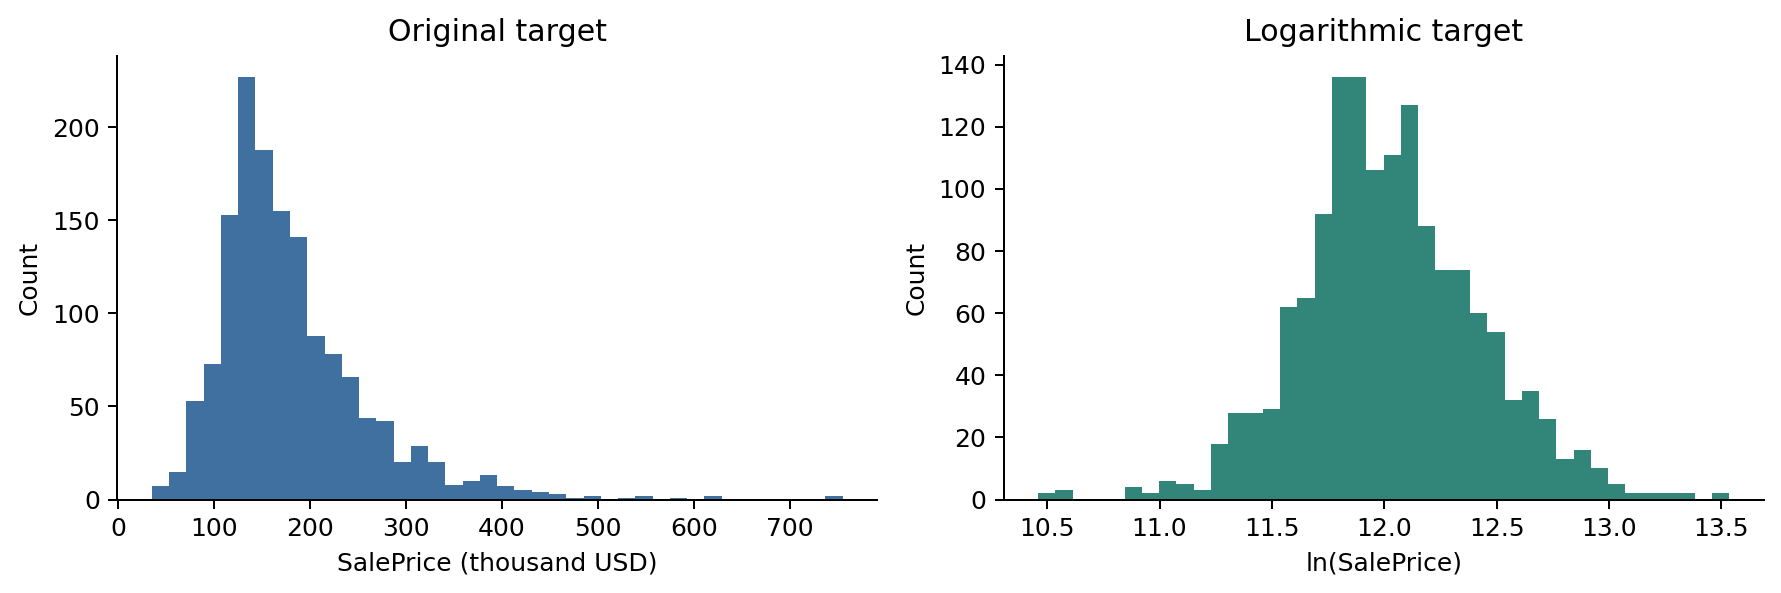

In [ ]:
display(Image(filename=str(OUT / "figures/target_distribution.png")))


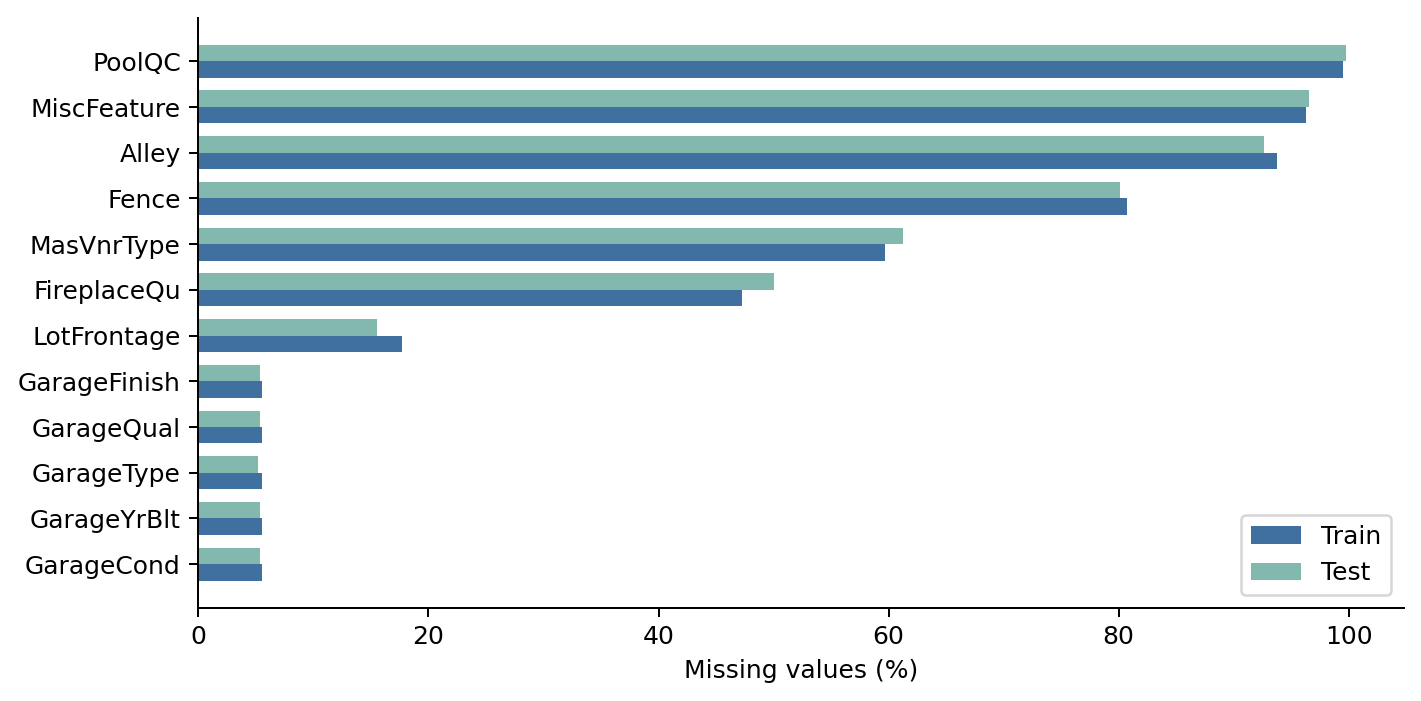

In [ ]:
display(pd.read_csv(OUT / "missingness.csv").head(12))
display(Image(filename=str(OUT / "figures/missingness.png")))


`NA` 在很多设施字段表示“不存在”。`LotFrontage` 用训练折内社区中位数回退全局中位数；其他填补、One-Hot、偏度筛选和缩放也只在训练折拟合。

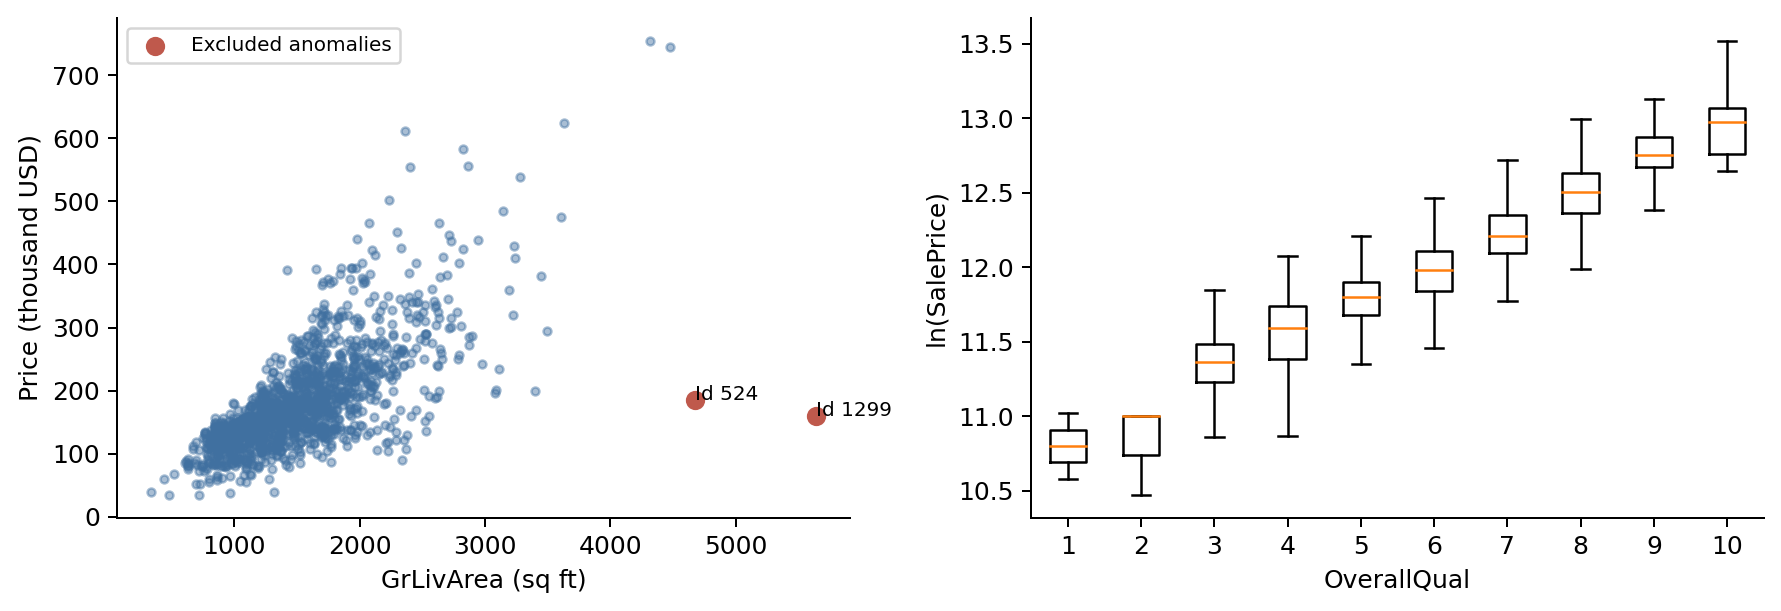

In [ ]:
display(Image(filename=str(OUT / "figures/area_quality.png")))


## 3. 折内特征工程

加入总面积、有效面积、卫生间数量、门廊面积、房龄、质量与面积交互、设施存在性和社区房型交互。非负长尾数值比较 log1p 与 Box-Cox(λ=0.15)，线性与核模型比较 RobustScaler 和 StandardScaler。

In [ ]:
from sklearn.model_selection import KFold
from experiment import Features
regular = train.loc[~((train.GrLivArea > 4000) & (train.SalePrice < 300000))].reset_index(drop=True)
ti, vi = next(KFold(5, shuffle=True, random_state=42).split(regular))
prep = Features("extended", "boxcox", rare=2).fit(regular.iloc[ti])
X_train = prep.matrix(regular.iloc[ti])
X_valid = prep.matrix(regular.iloc[vi])
X_test = prep.matrix(test)
assert set(regular.iloc[ti].Id).isdisjoint(regular.iloc[vi].Id)
print(X_train.shape, X_valid.shape, X_test.shape)


## 4. 模型比较与 Optuna 搜索

完成 55 组统一五折配置、40 次 Optuna 搜索。残差模型先拟合 Lasso，再用 XGBoost 学习对数价格残差。搜索最优四组重新做五折验证；原始三折搜索分数不直接混入五折对比。全部参数和剪枝状态均保存。

In [ ]:
scores = pd.read_csv(OUT / "all_experiments.csv")
display(scores.sort_values("rmse"))
trials = pd.read_csv(ROOT / "experiments/optuna/trials.csv")
display(trials[["number", "value", "state"]])


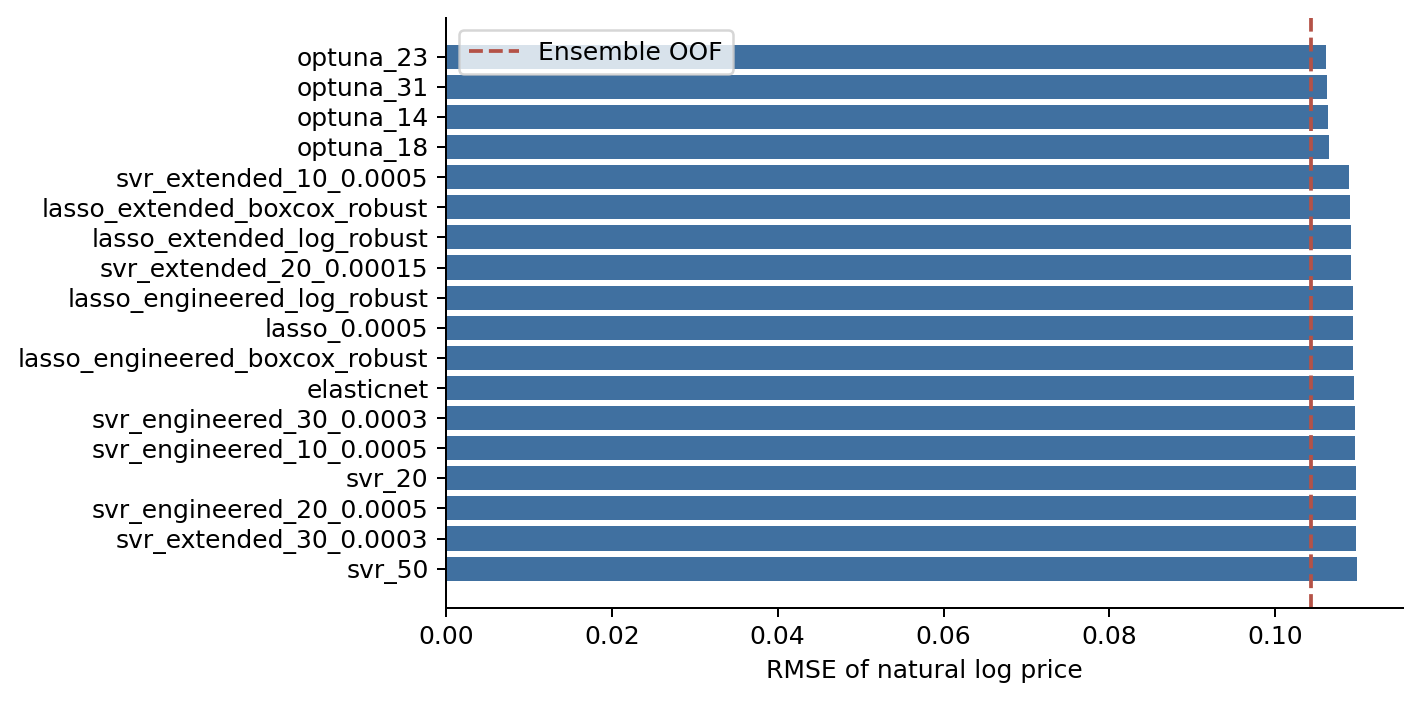

In [ ]:
display(Image(filename=str(OUT / "figures/model_comparison.png")))


## 5. 集成与新划分复验

利用折外预测求非负、和为 1 的权重，每个权重最多 0.55，加入轻微均匀权重收缩。主要为残差 XGBoost、SVR、XGBoost 和少量 CatBoost。冻结权重和训练轮数后新种子复验。重复划分复用了相同标签，属于稳定性检查；不能称为独立测试或无偏嵌套验证。

In [ ]:
validation = json.loads((OUT / "final_validation.json").read_text())
for name in ["selection", "confirmation", "all_rows_audit"]:
    print(name, validation[name]["rmse"], validation[name]["n_rows"])


selection 0.1043389378238206 1458
confirmation 0.104301574476552 1458
all_rows_audit 0.1241676897565335 1460


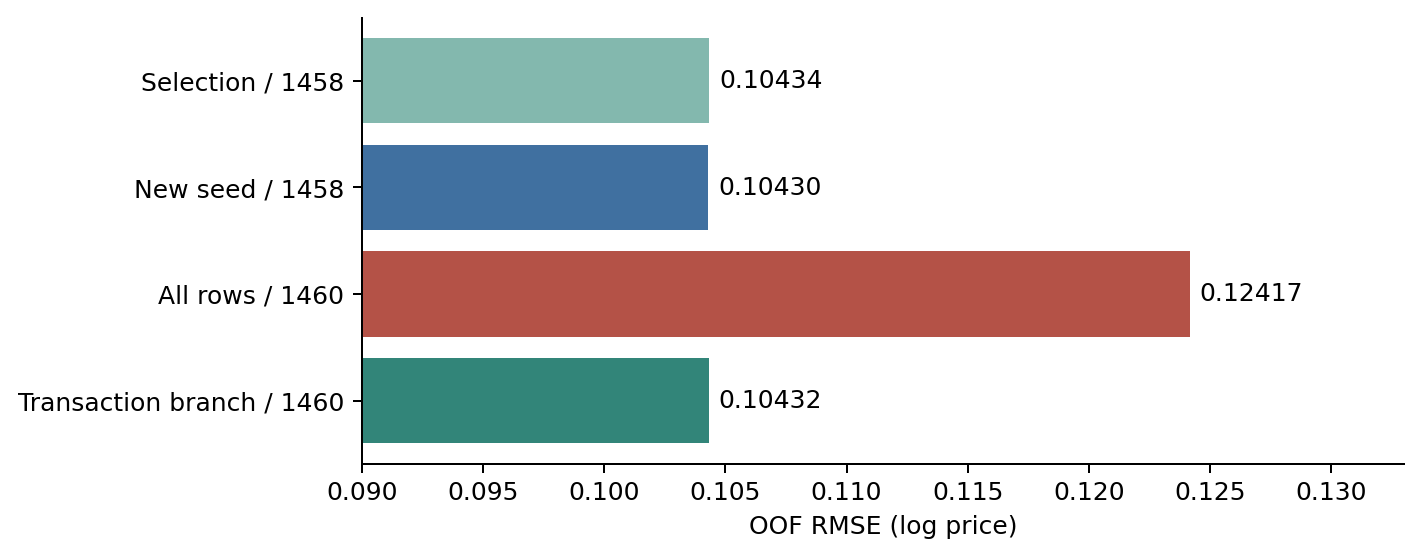

In [ ]:
display(Image(filename=str(OUT / "figures/validation_audit.png")))


## 6. 特殊交易分支

原基线删去的大面积低价记录均为 Partial 销售。普通模型在完整 1460 行验证中对这类房产严重高估。提出 `GrLivArea > 4000 and SaleCondition == Partial` 分支，按训练折同类交易对数均值预测。两条记录互相留出，预测各自不使用自身标签。阈值 3800/4000/4200/4500 触发相同样本。仅两条训练记录支持此假设，不能外推为普遍业务规律。触发条件依赖特征，不依赖测试 Id。

In [ ]:
branch = json.loads((OUT / "transaction_branch.json").read_text())
print("Full-row branch OOF:", branch["all_rows_branch_rmse"])
display(pd.DataFrame(branch["branch_leave_one_out"]))


Full-row branch OOF: 0.10432475735803212


## 7. 误差和真实线上迭代

v3 在本地优于 v2，线上却较差。多种子集成收益很小，特殊交易分支收益较大。结果按 API 返回评分记录，不以本地分数冒充线上分数。

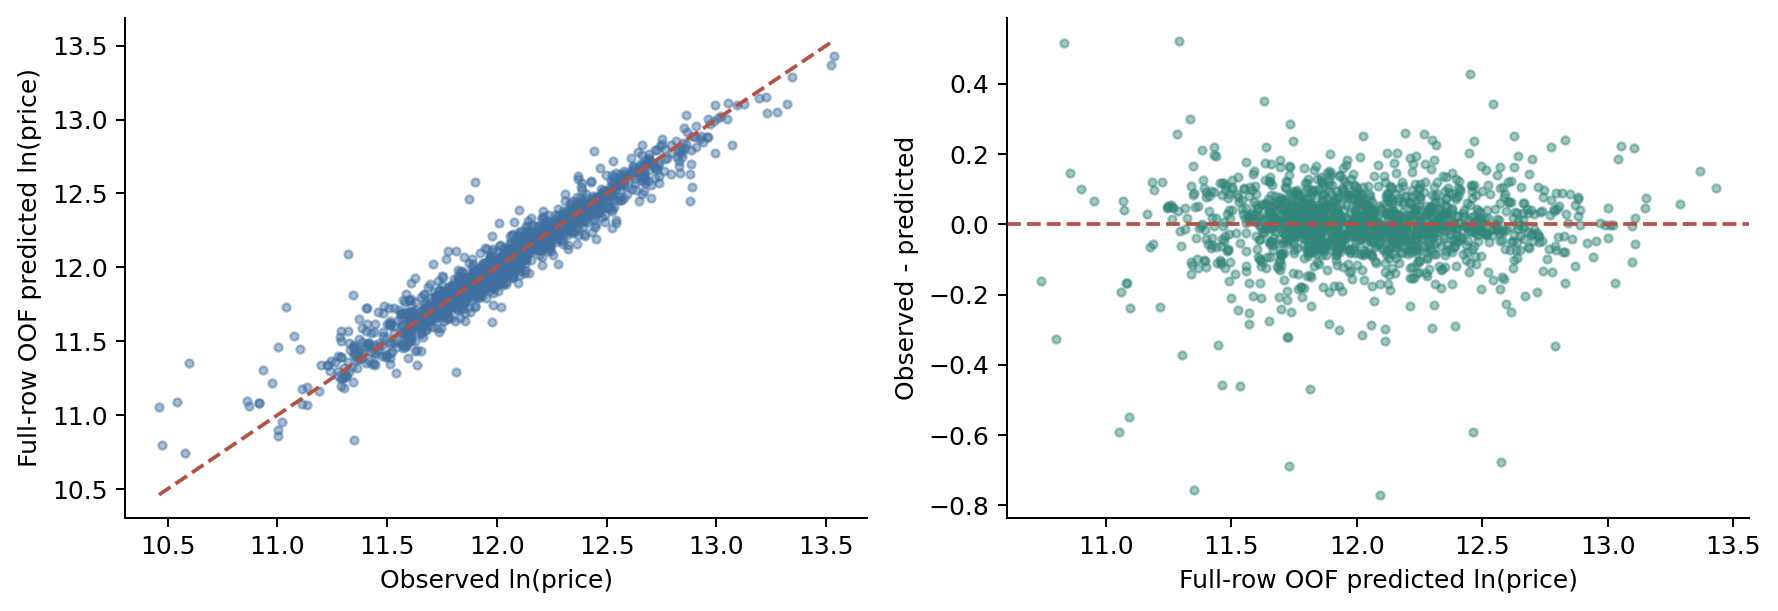

In [ ]:
display(Image(filename=str(OUT / "figures/final_residuals.png")))
display(pd.read_csv(OUT / "largest_errors.csv").head(10))


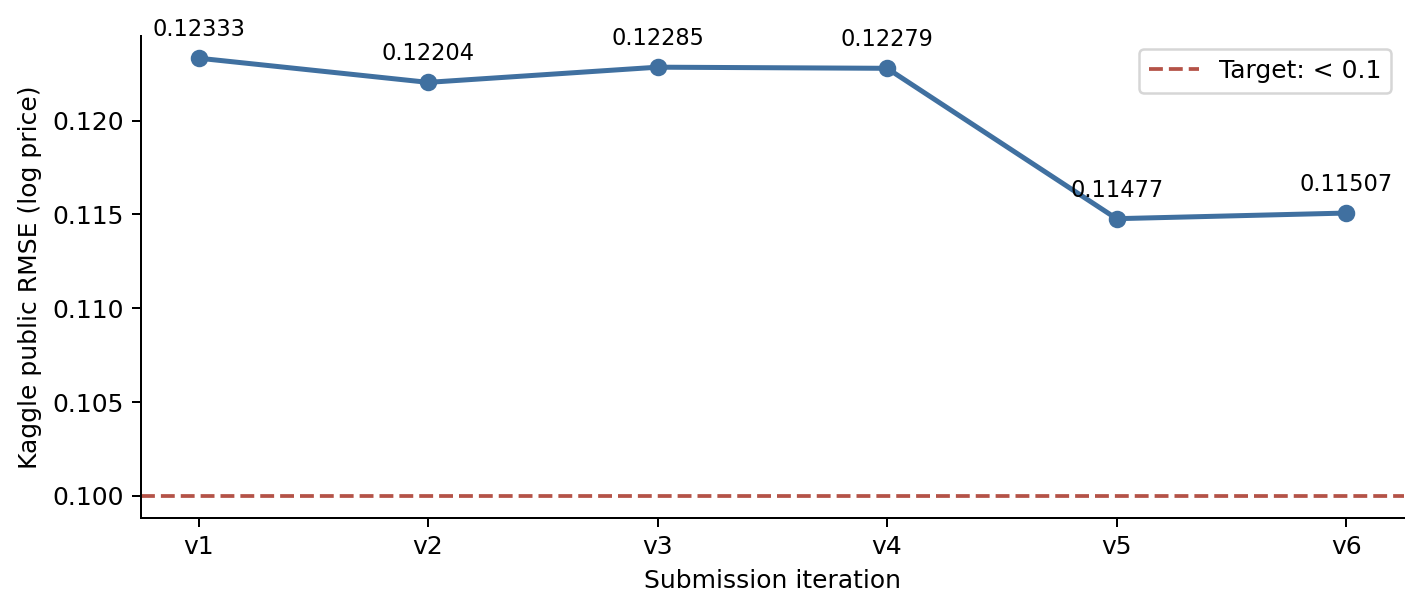

In [ ]:
records = json.loads((OUT / "kaggle_submissions.json").read_text())
display(pd.DataFrame(records)[["ref", "fileName", "publicScore", "status"]])
display(Image(filename=str(OUT / "figures/kaggle_iterations.png")))


## 8. 复现与提交检查

完整运行步骤见 README.md。`experiment.py`、`optimize.py`、`analyze.py`、`finalize.py`、`transaction_branch.py`、`train_final.py` 实现训练与预测。GPU 设备需按可用资源调整。模型保存在 `models/`；训练误差不是验证指标。认证 Token 通过进程环境提供，不写入本 Notebook。

In [ ]:
submission = pd.read_csv(ROOT / "submission.csv")
sample = pd.read_csv(ROOT / "data/sample_submission.csv")
assert list(submission.columns) == ["Id", "SalePrice"]
assert len(submission) == 1459
assert submission.Id.is_unique
assert np.array_equal(submission.Id, sample.Id)
assert (submission.SalePrice > 0).all() and np.isfinite(submission.SalePrice).all()
print("Submission schema and values verified.")


Submission schema and values verified.
